# 12 — MURA all-anatomy frozen ResNet-18 + Logistic Regression baseline

This is the required cheap baseline, trained **separately for each anatomy**. Each image passes through a frozen ImageNet ResNet-18; embeddings are mean-pooled within a study and Logistic Regression produces the study-level abnormality score.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

def locate_project_root():
    for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (candidate / "CHARTER.md").exists():
            return candidate
    raise RuntimeError("Run this notebook from inside the repository checkout.")

ROOT = locate_project_root()
RUNTIME = ROOT.parent / 'runtime' / 'multianatomy_v1'
MANIFESTS = RUNTIME / 'manifests'
QC = RUNTIME / 'qc'
BASELINE = RUNTIME / 'baseline_all_v1'
assert ROOT.name == 'mura-wrist-ml-pipeline', ROOT
print('Repository: local project checkout')
print('Runtime artifacts: local only (not committed to Git)')


Repository: local project checkout
Runtime artifacts: local only (not committed to Git)


In [2]:
baseline_provenance = json.loads((BASELINE / 'baseline_provenance.json').read_text(encoding='utf-8'))
assert baseline_provenance['official_valid_read'] is False
assert baseline_provenance['test_used_for_selection'] is False
display(Markdown('**Run check passed:** the baseline used only official train → internal train/validation.'))
display(pd.DataFrame([{
    'model': baseline_provenance['model'],
    'C selection': baseline_provenance['C_selection'],
    'operating policy': baseline_provenance['operating_policy'],
    'target sensitivity': baseline_provenance['target_sensitivity'],
    'device': baseline_provenance['device'],
    'runtime (seconds)': baseline_provenance['runtime_seconds'],
}]))

**Run check passed:** the baseline used only official train → internal train/validation.

,model,C selection,operating policy,target sensitivity,device,runtime (seconds)
0,Frozen ImageNet ResNet-18 embeddings + mean st...,5-fold patient-grouped CV inside each anatomy ...,highest validation threshold at sensitivity >=...,0.95,cuda,908.362


In [3]:
metrics = pd.read_csv(BASELINE / 'baseline_metrics_by_anatomy.csv')
display(metrics[[
    'anatomy', 'n_studies', 'selected_C', 'threshold', 'auroc', 'auprc',
    'sensitivity', 'specificity', 'precision', 'f1',
    'false_negative', 'false_positive', 'flagged_percent'
]].round(4))

,anatomy,n_studies,selected_C,threshold,auroc,auprc,sensitivity,specificity,precision,f1,false_negative,false_positive,flagged_percent
0,XR_ELBOW,345,0.1,0.0409,0.8550,0.8367,0.9538,0.2651,0.4397,0.6019,6,158,81.7391
1,XR_FINGER,392,0.1,0.0215,0.7465,0.6010,0.9535,0.2053,0.3705,0.5336,6,209,84.6939
2,XR_FOREARM,183,0.1,0.0493,0.8439,0.6861,0.9636,0.3672,0.3955,0.5608,2,81,73.2240
3,XR_HAND,411,0.1,0.0151,0.7123,0.5833,0.9533,0.0724,0.2656,0.4155,5,282,93.4307
4,XR_HUMERUS,118,0.1,0.0670,0.7948,0.7243,0.9636,0.4921,0.6235,0.7571,2,32,72.0339
5,XR_SHOULDER,567,0.1,0.1184,0.8124,0.8364,0.9522,0.2920,0.5899,0.7285,14,194,83.4215
6,XR_WRIST,708,0.1,0.0530,0.8655,0.8372,0.9522,0.3624,0.4823,0.6403,13,278,75.8475


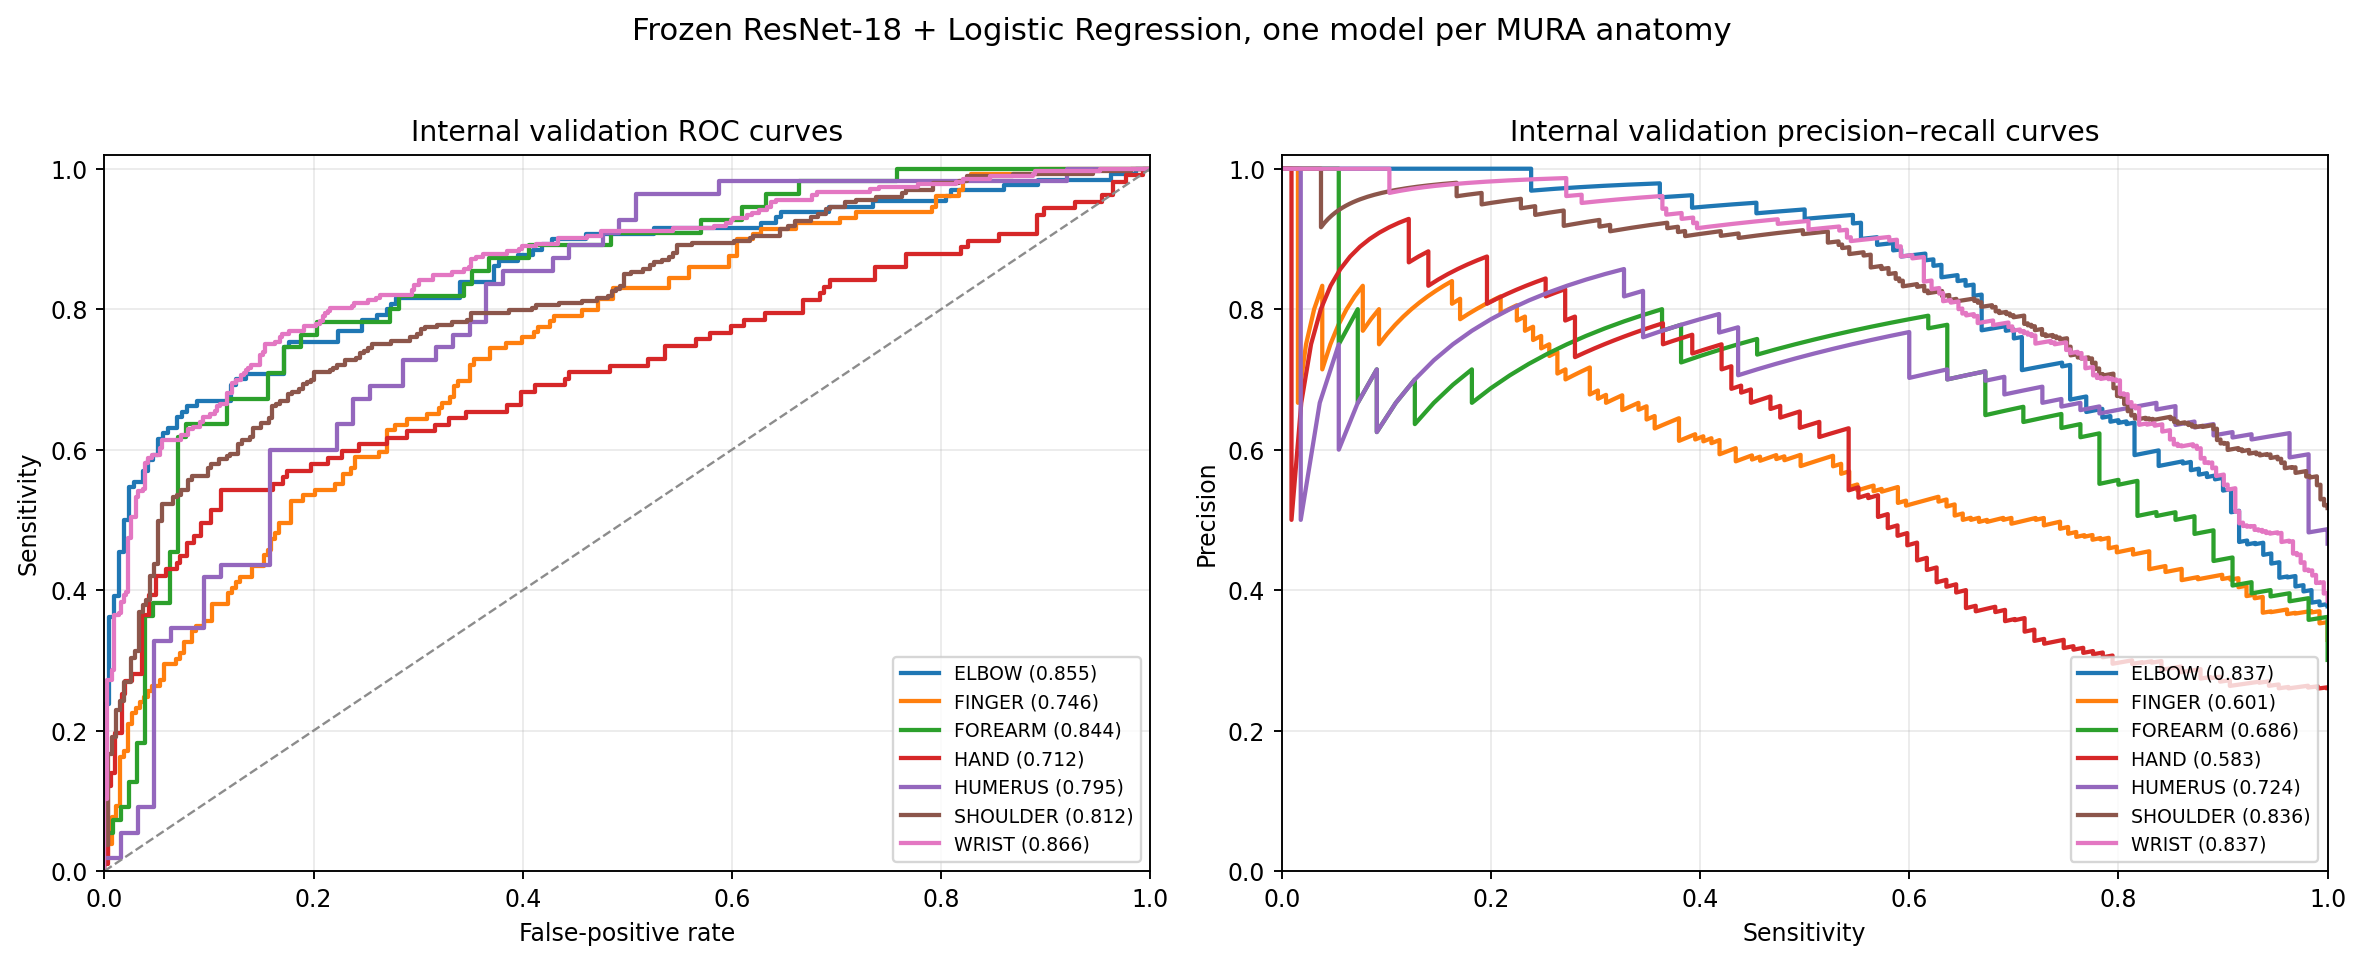

In [4]:
display(Image(filename=str(BASELINE / 'baseline_roc_pr_by_anatomy.png')))

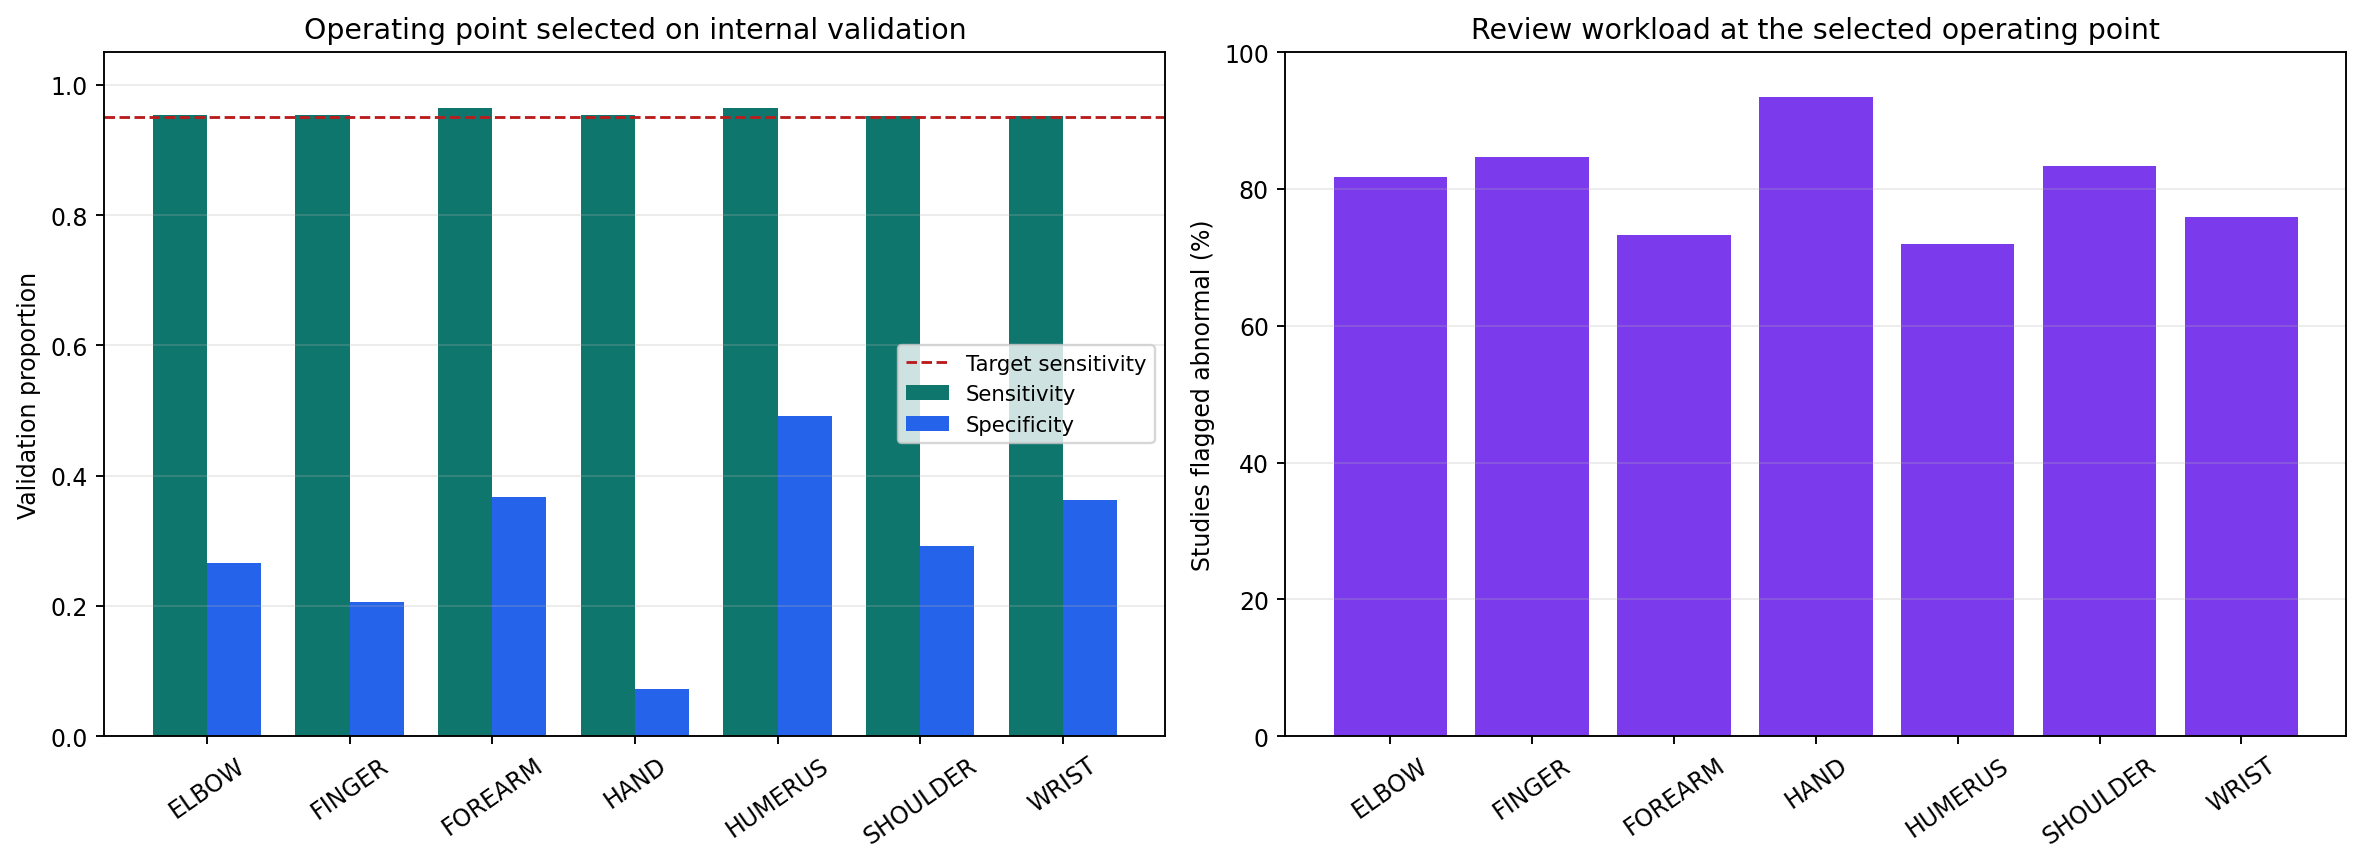

In [5]:
display(Image(filename=str(BASELINE / 'baseline_operating_point_workload.png')))

### How the threshold was chosen

The 95% sensitivity target was fixed before reporting the results. For each anatomy, the code considers all internal-validation study probabilities and chooses the **highest** threshold that still reaches at least 95% sensitivity. This maximizes specificity among thresholds meeting that target. The threshold is not transferred from one anatomy to another.